# 합성곱 신경망의 시각화

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import datasets
from torchinfo import summary

In [2]:
# 재현성
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


# GPU(집 PC) / CPU(노트북) 자동 선택
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


In [3]:
# 이전 코드와 동일한 구조 (Sequential 인덱스: 0=Conv, 1=ReLU, 2=Pool, 3=Conv, 4=ReLU, 5=Pool, ...)
model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(64*7*7, 100),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(100, 10),
).to(device)

best_cnn_model_path = './best-cnn-model.pt'
model.load_state_dict(torch.load(best_cnn_model_path, map_location=device))
model.eval()
list(model.children())  # model.layers 대체

[Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
 ReLU(),
 MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False),
 Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)),
 ReLU(),
 MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False),
 Flatten(start_dim=1, end_dim=-1),
 Linear(in_features=3136, out_features=100, bias=True),
 ReLU(),
 Dropout(p=0.4, inplace=False),
 Linear(in_features=100, out_features=10, bias=True)]

In [4]:
# ---------- 학습된 첫 번째 Conv 가중치 ----------
conv = model[0]
print(conv.weight.shape, conv.bias.shape)  # (32, 1, 3, 3), (32,)

conv_weights = conv.weight.detach().cpu().numpy()
print(conv_weights.mean(), conv_weights.std())
print(conv_weights.shape)
print(conv_weights.reshape(-1, 1).shape)

torch.Size([32, 1, 3, 3]) torch.Size([32])
-0.073180825 0.3964921
(32, 1, 3, 3)
(288, 1)


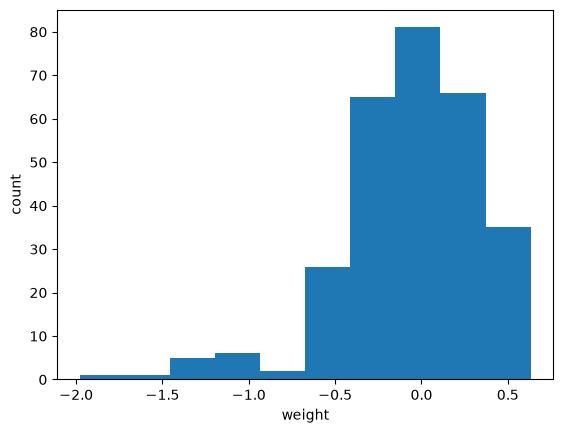

In [13]:
plt.hist(conv_weights.reshape(-1, 1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

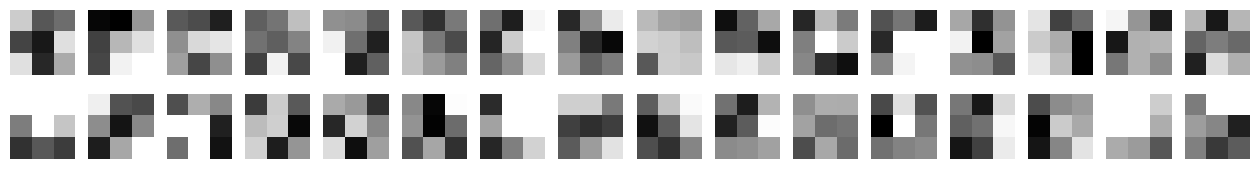

In [ ]:
fig, axes = plt.subplots(2, 16, figsize=(16, 2))
for i in range(2):
    for j in range(16):
        axes[i, j].imshow(conv_weights[i*16+j, 0], vmin=-0.5, vmax=0.5, cmap='gray_r')
        axes[i, j].axis('off')
plt.show()

In [15]:
# ---------- 학습 전(랜덤 초기화) Conv ----------
no_training_model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
)
list(no_training_model.children())

[Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)), ReLU()]

In [16]:
no_training_conv = no_training_model[0]
print(no_training_conv.weight.shape, no_training_conv.bias.shape)

no_training_weights = no_training_conv.weight.detach().numpy()
print(no_training_weights.mean(), no_training_weights.std())
print(no_training_weights.shape)
print(no_training_weights.reshape(-1, 1).shape)

torch.Size([32, 1, 3, 3]) torch.Size([32])
0.01190223 0.19226289
(32, 1, 3, 3)
(288, 1)


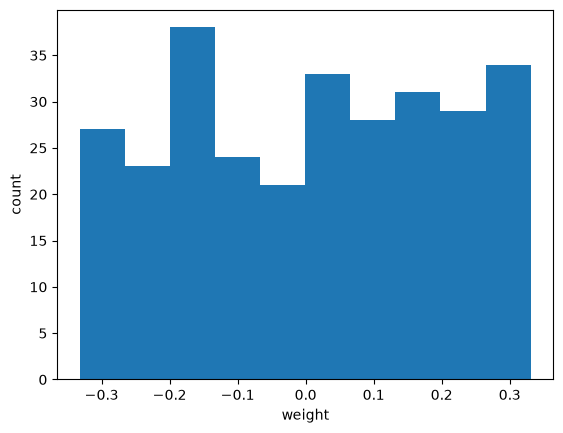

In [17]:
plt.hist(no_training_weights.reshape(-1, 1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

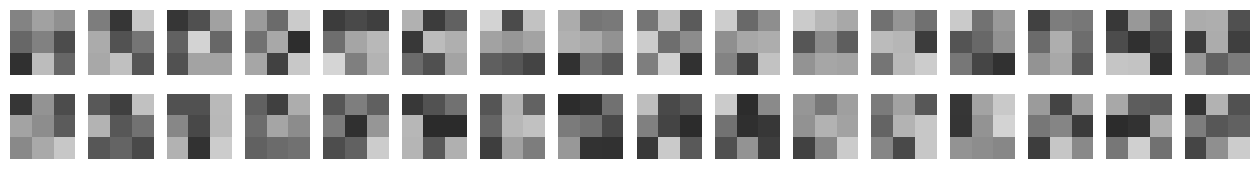

In [18]:
fig, axes = plt.subplots(2, 16, figsize=(16, 2))
for i in range(2):
    for j in range(16):
        axes[i, j].imshow(no_training_weights[i*16+j, 0], vmin=-0.5, vmax=0.5, cmap='gray_r')
        axes[i, j].axis('off')
plt.show()

In [19]:
# ---------- 첫 번째 Conv 활성화 (keras.Model(inputs, layers[0].output) 대체) ----------
conv_acti = model[:2]  # Conv + ReLU
summary(conv_acti, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 32, 28, 28]           --
├─Conv2d: 1-1                            [1, 32, 28, 28]           320
├─ReLU: 1-2                              [1, 32, 28, 28]           --
Total params: 320
Trainable params: 320
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.25
Input size (MB): 0.00
Forward/backward pass size (MB): 0.20
Params size (MB): 0.00
Estimated Total Size (MB): 0.21

In [20]:
# 데이터 로드 (keras.datasets.fashion_mnist 대체)
train_set = datasets.FashionMNIST(root='./data', train=True, download=True)
test_set = datasets.FashionMNIST(root='./data', train=False, download=True)

train_input, train_target = train_set.data.numpy(), train_set.targets.numpy()
test_input, test_target = test_set.data.numpy(), test_set.targets.numpy()
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


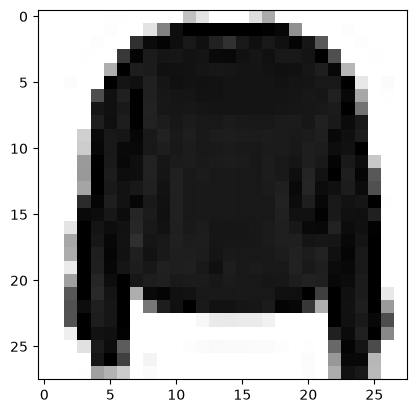

In [24]:
sample = 7
plt.imshow(train_input[sample], cmap='gray_r')
plt.show()

In [25]:
print(train_input[sample:sample+1].shape)
inputs = torch.tensor(train_input[sample:sample+1] / 255.0, dtype=torch.float32).unsqueeze(1).to(device)  # (1, 1, 28, 28)
print(inputs.shape)

(1, 28, 28)
torch.Size([1, 1, 28, 28])


In [26]:
# predict 대체
with torch.no_grad():
    feature_maps = conv_acti(inputs).cpu().numpy()
print(feature_maps.shape)  # (1, 32, 28, 28)

(1, 32, 28, 28)


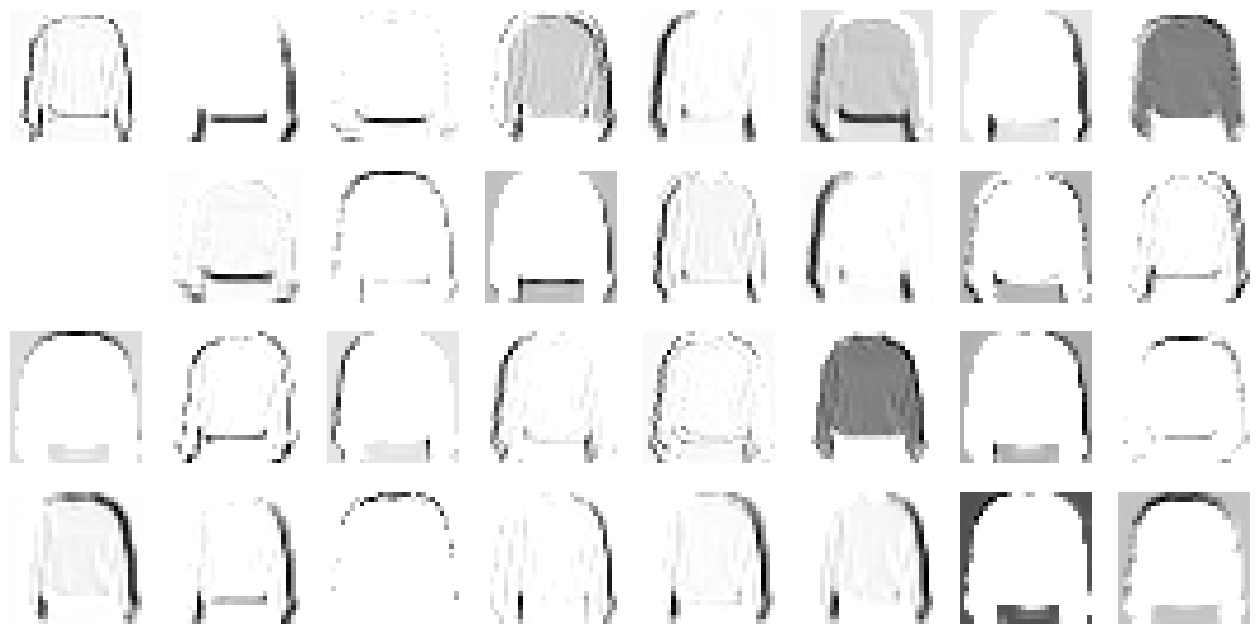

In [27]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i in range(4):
    for j in range(8):
        axes[i, j].imshow(feature_maps[0, i * 8 + j], cmap='gray_r')
        axes[i, j].axis('off')
plt.show()

In [28]:
# ---------- 두 번째 Conv 활성화 (keras.Model(inputs, layers[2].output) 대체) ----------
conv2_acti = model[:5]  # Conv -> ReLU -> Pool -> Conv -> ReLU
summary(conv2_acti, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 64, 14, 14]           --
├─Conv2d: 1-1                            [1, 32, 28, 28]           320
├─ReLU: 1-2                              [1, 32, 28, 28]           --
├─MaxPool2d: 1-3                         [1, 32, 14, 14]           --
├─Conv2d: 1-4                            [1, 64, 14, 14]           18,496
├─ReLU: 1-5                              [1, 64, 14, 14]           --
Total params: 18,816
Trainable params: 18,816
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 3.88
Input size (MB): 0.00
Forward/backward pass size (MB): 0.30
Params size (MB): 0.08
Estimated Total Size (MB): 0.38

In [29]:
print(train_input[sample:sample+1].shape)
inputs = torch.tensor(train_input[sample:sample+1] / 255.0, dtype=torch.float32).unsqueeze(1).to(device)
print(inputs.shape)

(1, 28, 28)
torch.Size([1, 1, 28, 28])


In [30]:
with torch.no_grad():
    feature_maps = conv2_acti(inputs).cpu().numpy()
print(feature_maps.shape)  # (1, 64, 14, 14)

(1, 64, 14, 14)


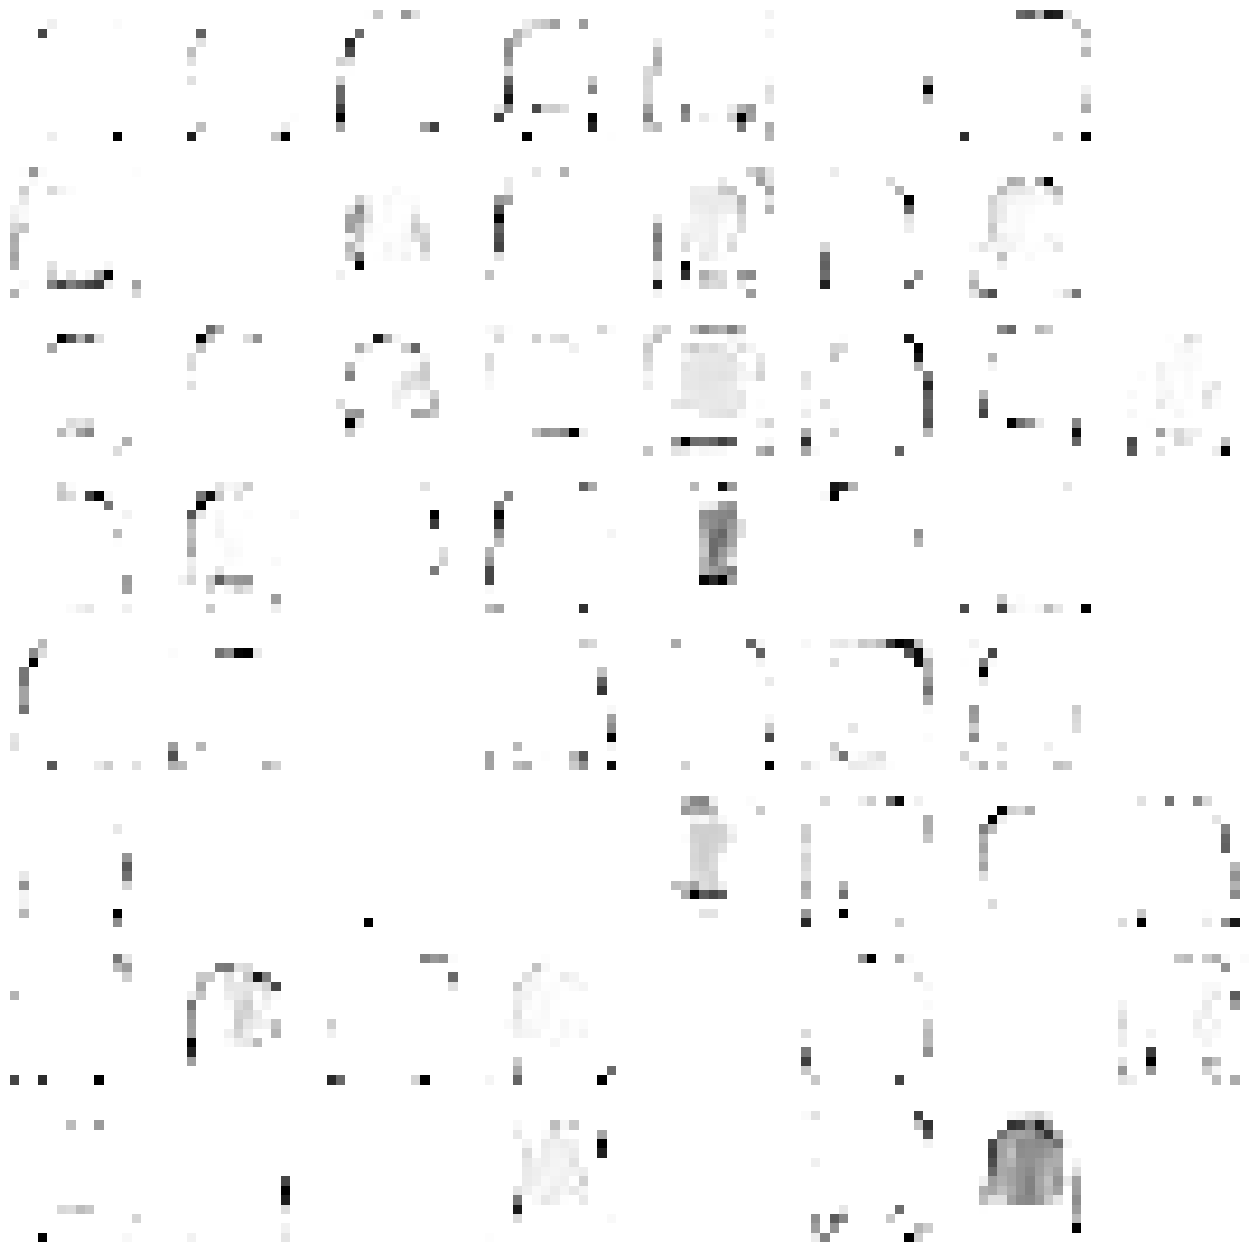

In [31]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))
for i in range(8):
    for j in range(8):
        axes[i, j].imshow(feature_maps[0, i*8+j], cmap='gray_r')
        axes[i, j].axis('off')
plt.show()